## Simulação de linhas equipotenciais em uma cuba eletrolítica a partir do método de diferenças finitas.

Dupla: Débora Azevedo e Marcos Vinicius Souza

#### Dimensões da malha

A cuba foi medida durante o experimento realizado com a turma, tendo 19cm x 19cm.

Vamos definir uma escala igual a 10. Essa escala será utilizada para criação da grade de nós utilizada para a aplicação do método, resultando em uma grade de 190 nós no eixo x e 190 nós no eixo y. Esse valor foi definido de forma a aumentar a precisão do método, uma vez que teremos nós nas extremidades dos eletrodos e nas bordas da cuba.

In [42]:
import matplotlib.pyplot as plt
import numpy as np

escala = 10
Nx = int(19 * escala)
Ny = int(19 * escala)

#### Inicialização da matriz de potencial e eletrodos

O método irá calcular o valor de tensão em cada ponto da matriz. Inicializamos como 5V para que a matriz não comece inteira zerada, evitando uma convergência falsa logo nas primeiras iterações.

Em seguida, configuramos a geometria do sistema. As regiões correspondentes aos dois eletrodos em formato de barra são delimitadas com base nas coordenadas físicas e armazenadas em uma matriz booleana denominada "eletrons". Dessa forma, os potenciais dos eletrodos são fixados nessas regiões e travados a cada passo do algoritmo, impedindo que o método iterativo altere os valores nesses nós.

In [43]:
V = np.ones((Ny, Nx)) * 5.0

# inicia com todos os pontos com "False"
eletrodos = np.zeros((Ny, Nx), dtype=bool)

y_ini = int(5.5 * escala)
y_fim = int(13.5 * escala)

# eletrodo esquerdo (0V)
x1_ini = int(5.2 * escala)
x1_fim = int(6.0 * escala)
V[y_ini:y_fim, x1_ini:x1_fim] = 0.0
eletrodos[y_ini:y_fim, x1_ini:x1_fim] = True

# eletrodo direito (10V)
x2_ini = int(13.0 * escala)
x2_fim = int(13.8 * escala)
V[y_ini:y_fim, x2_ini:x2_fim] = 10.0
eletrodos[y_ini:y_fim, x2_ini:x2_fim] = True


#### Método das diferenças finitas

Determinamos a quantidade de vizinhos que cada tipo de nó pode ter (por exemplo um nó na posição x = 0 e y = 0 na cuba terá apenas 2 vizinhos internos). Em seguida somamos os valores de tensão dos vizinhos internos do nó que estamos avaliando e fazemos a média, encontrando o novo valor de V do nó. O método é aplicado enquanto não é satisfeito o critério de parada (valor do erro).

In [44]:
# assume um valor de erro inicial para entrar no loop
error = 1.0
tolerance = 0.0001
# utilizado para calcular em quantas iterações o algoritmo atingiu o critério de parada
iteracao = 0

historico_erro = [] 

# determina a quantidade de vizinhos que cada nó tem 
n_viz = np.full((Ny, Nx), 4.0)    # interior: 4 vizinhos
n_viz[0, :]  -= 1                 # parede de baixo
n_viz[-1, :] -= 1                 # parede de cima
n_viz[:, 0]  -= 1                 # parede da esquerda
n_viz[:, -1] -= 1                 # parede da direita

while error > tolerance:
  V_old = V.copy()

  # soma dos vizinhos que existem
  soma = np.zeros_like(V_old)
  soma[1:, :]  += V_old[:-1, :]    # vizinho de baixo
  soma[:-1, :] += V_old[1:, :]     # vizinho de cima
  soma[:, 1:]  += V_old[:, :-1]    # vizinho da esquerda
  soma[:, :-1] += V_old[:, 1:]     # vizinho da direita

  # calcula a médias dos vizinhos
  V = soma / n_viz

  # Corrige o valor dos eletrodos (não devem mudar durante as iterações)
  V[y_ini:y_fim, x1_ini:x1_fim] = 0.0
  V[y_ini:y_fim, x2_ini:x2_fim] = 10.0

  # cálculo do erro (ignorando os eletrodos fixos)
  diff = np.abs(V - V_old)
  diff[eletrodos] = 0.0
  error = np.sum(diff) / np.sum(~eletrodos)
  historico_erro.append(error)
  iteracao += 1

print(
    f"Simulação concluída após {iteracao} iterações. Erro final: {error:.5f} V"
)

Simulação concluída após 8100 iterações. Erro final: 0.00010 V


#### Plota as curvas equipotenciais

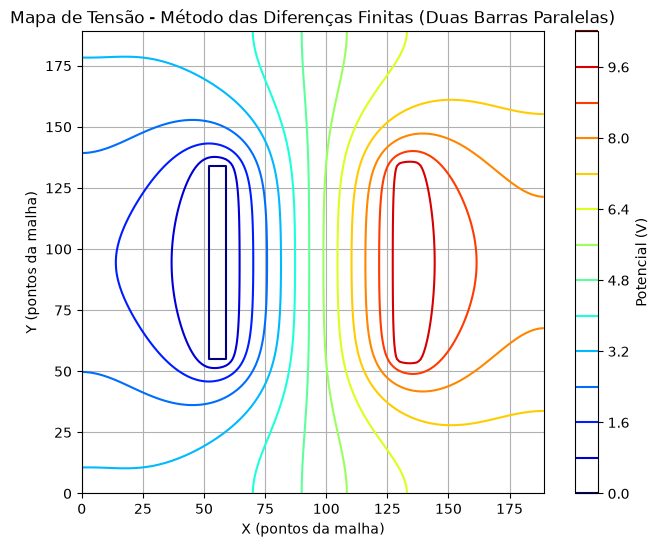

In [45]:
plt.figure(figsize=(8, 6))
cp = plt.contour(V, levels=15, cmap="jet")
plt.colorbar(cp, label="Potencial (V)")
plt.title(
    "Mapa de Tensão - Método das Diferenças Finitas (Duas Barras Paralelas)"
)
plt.xlabel("X (pontos da malha)")
plt.ylabel("Y (pontos da malha)")
plt.grid(True)
plt.gca().set_aspect("equal")
plt.show()

#### Plota gráfico do erro em cada iteração

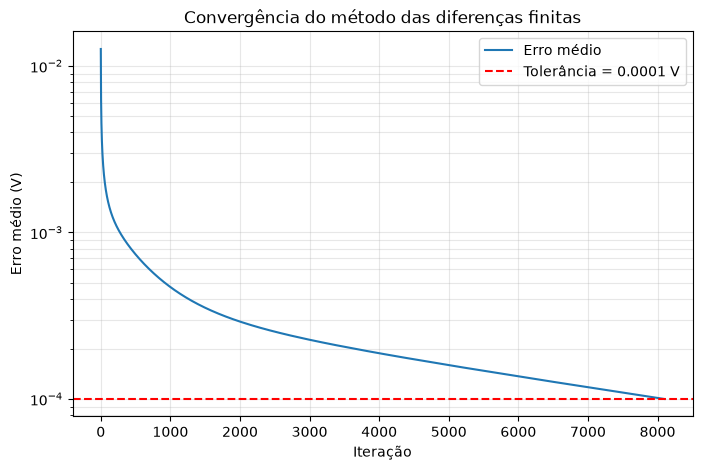

In [46]:
plt.figure(figsize=(8, 5))
plt.semilogy(historico_erro, label="Erro médio")
plt.axhline(tolerance, color="r", linestyle="--", label=f"Tolerância = {tolerance} V")
plt.xlabel("Iteração")
plt.ylabel("Erro médio (V)")
plt.title("Convergência do método das diferenças finitas")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

#### Plota gráfico de Linhas Equipotencias e Linhas do Campo Elétrico

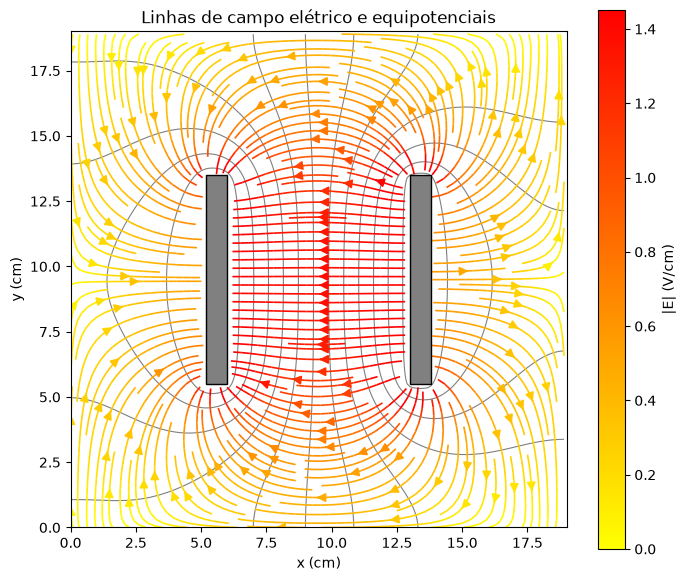

In [ ]:
import matplotlib.patches as patches

dx = 1.0 / escala                    # passo da malha em cm
Ey, Ex = np.gradient(-V, dx, dx)     # calcula o campo em cada ponto da malha
E_mag = np.hypot(Ex, Ey)

x = np.arange(Nx) / escala           # eixos em cm
y = np.arange(Ny) / escala

# mascara os eletrodos: as linhas terminam na superfície deles
Ex_m = np.ma.masked_where(eletrodos, Ex)
Ey_m = np.ma.masked_where(eletrodos, Ey)
E_cor = np.ma.masked_where(eletrodos, E_mag)

fig, ax = plt.subplots(figsize=(8, 7))

# equipotenciais ao fundo, em cinza
ax.contour(x, y, V, levels=15, colors="gray", linewidths=0.8)

# linhas de campo, coloridas pela intensidade
sp = ax.streamplot(
    x, y, Ex_m, Ey_m,
    color=E_cor, cmap="autumn_r",
    norm=plt.Normalize(0, np.percentile(E_mag[~eletrodos], 95)),
    density=2, linewidth=1.2, arrowsize=1.3,
)
fig.colorbar(sp.lines, ax=ax, label="|E| (V/cm)")

# eletrodos (posições e tamanhos em cm)
ax.add_patch(patches.Rectangle((5.2, 5.5), 0.8, 8, facecolor="gray", edgecolor="black", zorder=5))
ax.add_patch(patches.Rectangle((13.0, 5.5), 0.8, 8, facecolor="gray", edgecolor="black", zorder=5))

ax.set_xlim(0, 19)
ax.set_ylim(0, 19)
ax.set_aspect("equal")
ax.set_xlabel("x (cm)")
ax.set_ylabel("y (cm)")
ax.set_title("Linhas de campo elétrico e equipotenciais")
plt.savefig("linhas_campo.png", dpi=200, bbox_inches="tight")   # antes do show
    plt.show()